<a href="https://colab.research.google.com/github/RohitRevankarDev/AML-Assignment-261100610035/blob/main/1d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

# Load the Breast Cancer dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Target classes:", data.target_names)

display(X.head())


Dataset shape: (569, 30)
Number of features: 30
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 455
Testing samples: 114


In [ ]:

# Standardize features and apply KNN with K=5
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully.")


KNN model trained successfully.


In [ ]:

y_pred = knn_model.predict(X_test)
y_prob = knn_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")
print("First 10 actual values:", y_test.iloc[:10].to_list())
print("First 10 predicted values:", y_pred[:10].tolist())


Predictions generated successfully.
First 10 actual values: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]
First 10 predicted values: [0, 1, 0, 0, 0, 1, 1, 0, 0, 0]


In [ ]:

print("KNN Classification Performance")
print("------------------------------")

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


KNN Classification Performance
------------------------------
Accuracy : 0.9561
Precision: 0.9589
Recall   : 0.9722
F1 Score : 0.9655

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



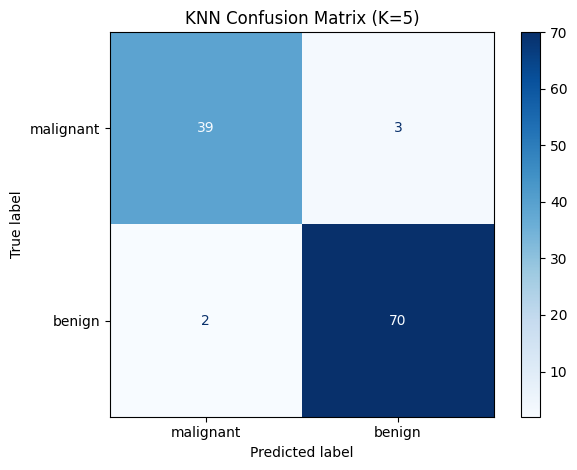

In [ ]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    cmap="Blues"
)

plt.title("KNN Confusion Matrix (K=5)")
plt.tight_layout()
plt.show()


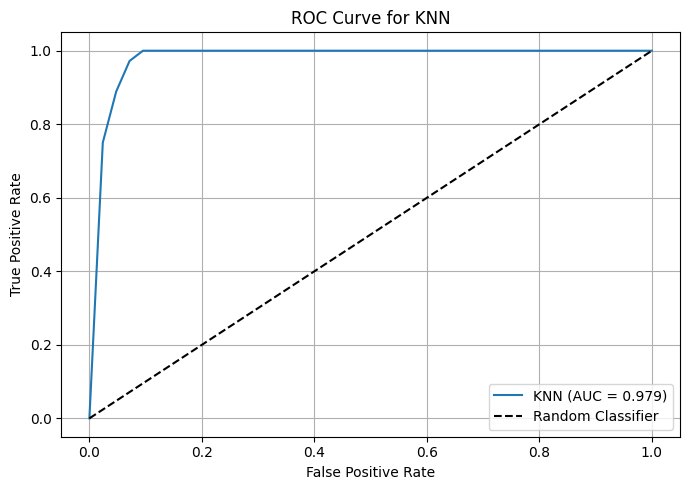

AUC Score: 0.9788


In [ ]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for KNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("AUC Score:", round(auc_score, 4))


In [ ]:

cv_scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", np.round(cv_scores, 4))
print("Mean CV accuracy:", round(cv_scores.mean(), 4))


Cross-validation scores: [0.9451 1.     0.9451 0.978  0.967 ]
Mean CV accuracy: 0.967


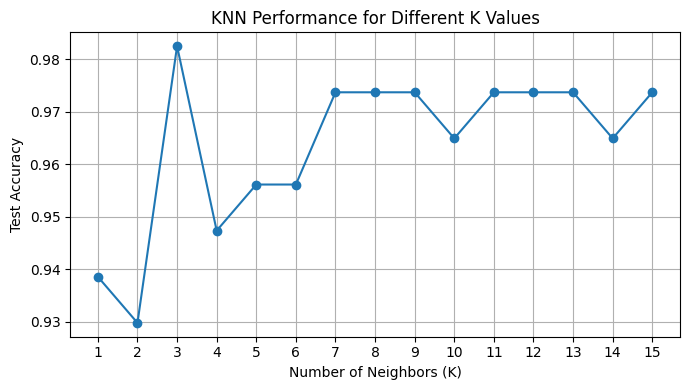

Best K among tested values: 3


In [ ]:

k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracies.append(accuracy_score(y_test, predictions))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), accuracies, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.title("KNN Performance for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

best_k = list(k_values)[np.argmax(accuracies)]
print("Best K among tested values:", best_k)



## Result

The K-Nearest Neighbors classification algorithm was implemented using the Breast Cancer dataset. The features were standardized, and the model was trained using K=5. Performance was evaluated using accuracy, precision, recall, F1-score, a confusion matrix, ROC curve, AUC and five-fold cross-validation. Different values of K were also compared.

## Conclusion

The experiment demonstrates how KNN classifies data based on distances between samples. Feature scaling and the choice of K affect model performance.
